## Name - Peiris.T.S.R
## Index no -230470U

repo https://github.com/angstrom10/EN3160---Image-Processing-and-Machine-Vision

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import copy

# Q1

Epoch 1/20, Loss: 0.9769463900923729
Epoch 2/20, Loss: 0.9498340966105461
Epoch 3/20, Loss: 0.9360930688977241
Epoch 4/20, Loss: 0.9275386862158775
Epoch 5/20, Loss: 0.9216004702448845
Epoch 6/20, Loss: 0.9171967073082924
Epoch 7/20, Loss: 0.9137833626270294
Epoch 8/20, Loss: 0.911056309580803
Epoch 9/20, Loss: 0.9088273193240166
Epoch 10/20, Loss: 0.9069748151898384
Epoch 11/20, Loss: 0.9054148703217506
Epoch 12/20, Loss: 0.9040878971219063
Epoch 13/20, Loss: 0.9029489221572876
Epoch 14/20, Loss: 0.901965576171875
Epoch 15/20, Loss: 0.9011115101575852
Epoch 16/20, Loss: 0.9003665674328803
Epoch 17/20, Loss: 0.8997139829397202
Epoch 18/20, Loss: 0.8991404904723167
Epoch 19/20, Loss: 0.8986349785923958
Epoch 20/20, Loss: 0.8981884378194809


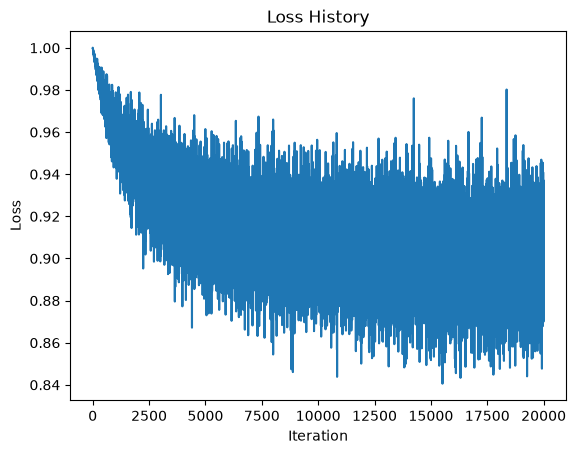

Training accuracy: 32.24%
Test accuracy: 32.45%


In [30]:


# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data/cifar10',
    train=True,
    download=False,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)
testset = torchvision.datasets.CIFAR10(
    root='./data/cifar10',
    train=False,
    download=False,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std  # One layer: directly map input to output
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot

        # Forward pass
        y_pred = x_train.mm(w) + b  # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Epoch 1/10 | Loss: 1.9774 | Training accuracy: 35.84% | Test accuracy: 36.13%
Epoch 2/10 | Loss: 1.8321 | Training accuracy: 38.24% | Test accuracy: 37.96%
Epoch 3/10 | Loss: 1.7883 | Training accuracy: 39.07% | Test accuracy: 38.88%
Epoch 4/10 | Loss: 1.7625 | Training accuracy: 39.72% | Test accuracy: 39.69%
Epoch 5/10 | Loss: 1.7444 | Training accuracy: 40.05% | Test accuracy: 39.72%
Epoch 6/10 | Loss: 1.7308 | Training accuracy: 40.57% | Test accuracy: 40.28%
Epoch 7/10 | Loss: 1.7201 | Training accuracy: 41.05% | Test accuracy: 40.74%
Epoch 8/10 | Loss: 1.7109 | Training accuracy: 41.24% | Test accuracy: 40.99%
Epoch 9/10 | Loss: 1.7039 | Training accuracy: 41.56% | Test accuracy: 41.02%
Epoch 10/10 | Loss: 1.6977 | Training accuracy: 41.72% | Test accuracy: 41.16%


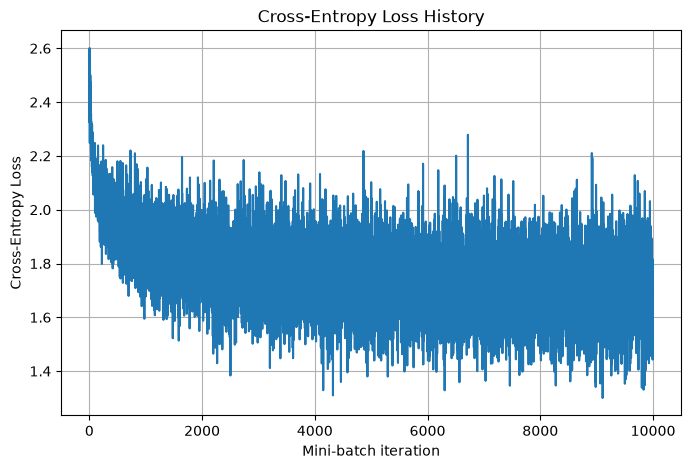

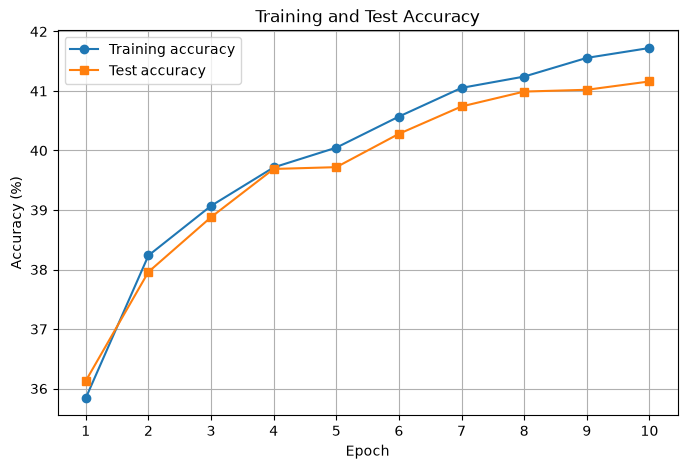

Final training accuracy: 41.72%
Final test accuracy: 41.16%


In [ ]:

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Select GPU if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Dataloading (use already downloaded CIFAR-10)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data/cifar10',
    train=True,
    download=False,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data/cifar10',
    train=False,
    download=False,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

# 2. Define Network Parameters
Din = 3 * 32 * 32
H = 100
K = 10


w1 = (torch.randn(Din, H) * (2.0 / (Din + H)) ** 0.5).to(device)
b1 = torch.zeros(H, device=device)

w2 = (torch.randn(H, K) * (2.0 / (H + K)) ** 0.5).to(device)
b2 = torch.zeros(K, device=device)

# Hyperparameters
iterations = 10
lr = 0.01
lr_decay = 0.9
reg = 0.0

loss_history = []
train_acc_history = []
test_acc_history = []

# 3. Training Loop: manual forward and backward propagation
for t in range(iterations):
    running_loss = 0.0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        N = inputs.shape[0]
        x = inputs.view(N, -1)

        y_onehot = nn.functional.one_hot(
            labels, K
        ).float()

        # Forward pass: input -> sigmoid hidden layer
        z1 = x.mm(w1) + b1
        h = torch.sigmoid(z1)

        # Hidden layer -> output logits
        logits = h.mm(w2) + b2

        # Softmax probabilities (numerically stable)
        shifted_logits = logits - logits.max(
            dim=1, keepdim=True
        ).values

        exp_logits = torch.exp(shifted_logits)
        probs = exp_logits / exp_logits.sum(
            dim=1, keepdim=True
        )

        # Cross-entropy loss
        loss = -torch.sum(
            y_onehot * torch.log(probs.clamp_min(1e-12))
        ) / N

        loss = loss + 0.5 * reg * (
            torch.sum(w1 ** 2) + torch.sum(w2 ** 2)
        )

        running_loss += loss.item()
        loss_history.append(loss.item())

        # Backpropagation: output layer
        dlogits = (probs - y_onehot) / N

        dw2 = h.t().mm(dlogits) + reg * w2
        db2 = dlogits.sum(dim=0)

        # Backpropagation: sigmoid hidden layer
        dh = dlogits.mm(w2.t())
        dz1 = dh * h * (1.0 - h)

        dw1 = x.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter updates
        w1 -= lr * dw1
        b1 -= lr * db1

        w2 -= lr * dw2
        b2 -= lr * db2

    # Calculate training accuracy
    correct_train = 0
    total_train = 0

    with torch.no_grad():
        for inputs, labels in trainloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            N = inputs.shape[0]
            x = inputs.view(N, -1)

            hidden = torch.sigmoid(x.mm(w1) + b1)
            scores = hidden.mm(w2) + b2

            predictions = torch.argmax(scores, dim=1)
            correct_train += (predictions == labels).sum().item()
            total_train += labels.size(0)

    train_acc = 100.0 * correct_train / total_train
    train_acc_history.append(train_acc)

    # Calculate test accuracy
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            N = inputs.shape[0]
            x = inputs.view(N, -1)

            hidden = torch.sigmoid(x.mm(w1) + b1)
            scores = hidden.mm(w2) + b2

            predictions = torch.argmax(scores, dim=1)
            correct_test += (predictions == labels).sum().item()
            total_test += labels.size(0)

    test_acc = 100.0 * correct_test / total_test
    test_acc_history.append(test_acc)

    print(
        f"Epoch {t + 1}/{iterations} | "
        f"Loss: {running_loss / len(trainloader):.4f} | "
        f"Training accuracy: {train_acc:.2f}% | "
        f"Test accuracy: {test_acc:.2f}%"
    )

    lr *= lr_decay

# 4. Plot mini-batch training loss
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Cross-Entropy Loss History")
plt.xlabel("Mini-batch iteration")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()



print(f"Final training accuracy: {train_acc_history[-1]:.2f}%")
print(f"Final test accuracy: {test_acc_history[-1]:.2f}%")


The hidden-layer network achieved a test accuracy of **41.16%** after 10 epochs, with a training accuracy of **41.72%**. Although the loss decreased throughout training, the model learned relatively slowly. This may be due to the additional hidden layer and the choice of learning rate, which affect how efficiently the weights are updated during backpropagation. Increasing the learning rate can improve convergence and potentially bring the performance closer to that of the original single-layer network.

# Q2


Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Epoch 1/10 | Train Loss: 0.2606 | Train Accuracy: 92.67% | Test Loss: 0.0833 | Test Accuracy: 97.42%
Epoch 2/10 | Train Loss: 0.0739 | Train Accuracy: 97.74% | Test Loss: 0.0512 | Test Accuracy: 98.40%
Epoch 3/10 | Train Loss: 0.0526 | Train Accuracy: 98.41% | Test Loss: 0.0444 | Test Accuracy: 98.57%
Epoch 4/10 | Train Loss: 0.0423 | Train Accuracy: 98.68% | Test Loss: 0.0397 | Test Accuracy: 98.81%
Epoch 5/10 | Train Loss: 0.0331 | Train Accuracy: 98.94% | Test Loss: 0.0387 | Test Accuracy: 98.80%
Epoch 6/10 | Train Loss: 0.0287 | Train Accuracy: 99.09% | Test Loss: 0.0388 | Test Accuracy: 98.78%
Epoch 7/10 | Train Loss: 0.0241 | Train Accuracy: 99.20% | Test Loss: 0.0339 | Test Accuracy: 99.02%
Epoch 8/10 | Train Loss: 0.0206 | Train Accuracy: 99.36% | Test Loss: 0.0336 | Test Accuracy: 98.93%
Epoch 9/10 | Train Loss: 0.0177 | Train Accuracy: 99.42% | Test Loss: 0.0399 | Test Accuracy: 98.68%
Epoch 10/10 | Train Loss: 0.0147

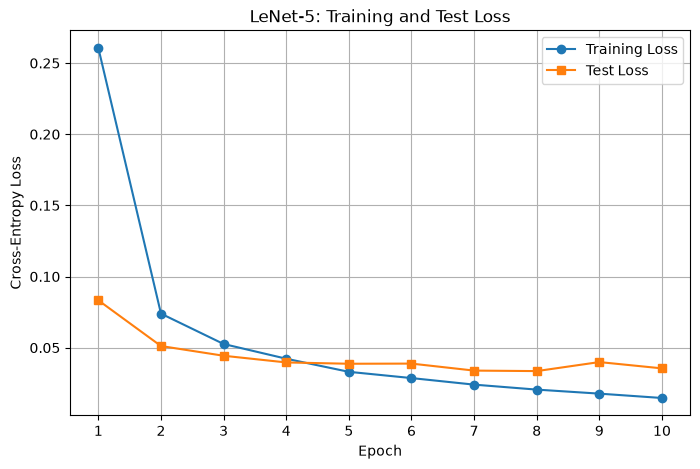

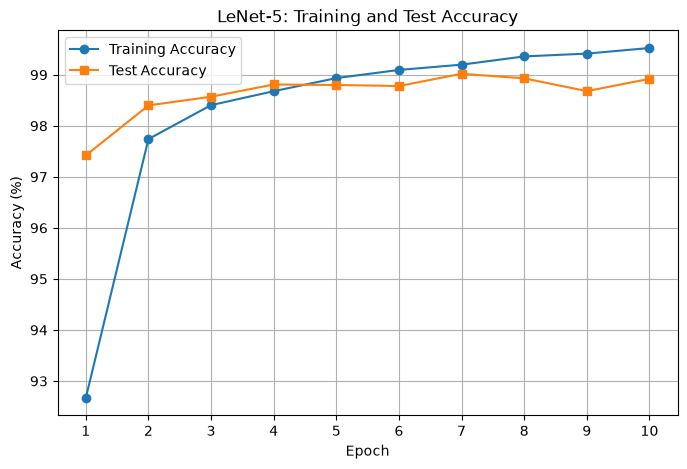

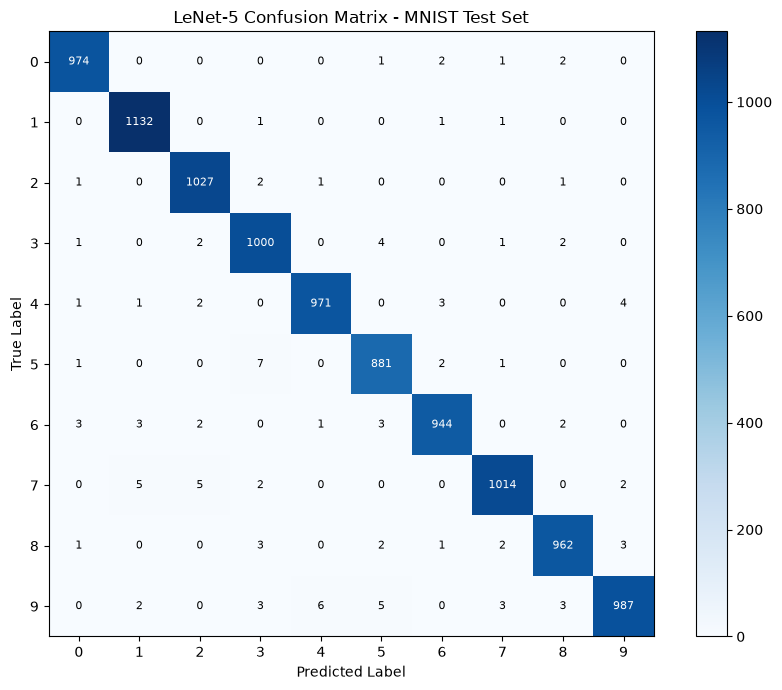

Final LeNet-5 training accuracy: 99.53%
Final LeNet-5 test accuracy: 98.92%


In [34]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# 1. Load the already downloaded MNIST dataset

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(
    root='./data/mnist',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.MNIST(
    root='./data/mnist',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)


# 2. Define LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

        self.activation = nn.Tanh()

    def forward(self, x):
        x = self.activation(self.conv1(x))
        x = self.pool1(x)

        x = self.activation(self.conv2(x))
        x = self.pool2(x)

        x = torch.flatten(x, 1)

        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.fc3(x)

        return x


model = LeNet5().to(device)

# 3. Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# 4. Training and evaluation
for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100.0 * correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Testing
    model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct_test += (predictions == labels).sum().item()
            total_test += labels.size(0)

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = 100.0 * correct_test / total_test

    test_losses.append(epoch_test_loss)
    test_accuracies.append(epoch_test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_acc:.2f}% | "
        f"Test Loss: {epoch_test_loss:.4f} | "
        f"Test Accuracy: {epoch_test_acc:.2f}%"
    )

# 5. Plot training and test loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, marker='o',
         label='Training Loss')
plt.plot(range(1, epochs + 1), test_losses, marker='s',
         label='Test Loss')
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("LeNet-5: Training and Test Loss")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()

# 6. Plot training and test accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_accuracies, marker='o',
         label='Training Accuracy')
plt.plot(range(1, epochs + 1), test_accuracies, marker='s',
         label='Test Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("LeNet-5: Training and Test Accuracy")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()

# 7. Confusion matrix on the test set
confusion_matrix = torch.zeros(10, 10, dtype=torch.int64)

model.eval()

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        # Rows = true labels, columns = predicted labels
        indices = labels * 10 + predictions
        counts = torch.bincount(indices.cpu(), minlength=100)
        confusion_matrix += counts.reshape(10, 10)

plt.figure(figsize=(9, 7))
plt.imshow(confusion_matrix.numpy(), cmap='Blues')
plt.title("LeNet-5 Confusion Matrix - MNIST Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

for i in range(10):
    for j in range(10):
        value = confusion_matrix[i, j].item()
        plt.text(
            j, i, str(value),
            ha='center', va='center',
            color='white' if value > confusion_matrix.max().item() * 0.5
            else 'black',
            fontsize=8
        )

plt.tight_layout()
plt.show()

# 8. Final results
print(f"Final LeNet-5 training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final LeNet-5 test accuracy: {test_accuracies[-1]:.2f}%")


In [36]:

# Q2(b): Modern CNN

class ModernSmallCNN(nn.Module):
    """Three convolutional layers with batch normalization and pooling."""

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Convolutional layer 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 -> 16

            # Convolutional layer 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16 -> 8

            # Convolutional layer 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 8 -> 4

            nn.Dropout2d(p=0.15)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.35),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


modern_cnn = ModernSmallCNN().to(device)

print(modern_cnn)
print("Using device:", device)


ModernSmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout2d(p=0.15, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=6

Using device: cuda
Epoch 1/10 | Train Loss: 0.2109 | Train Accuracy: 93.69% | Test Loss: 0.0672 | Test Accuracy: 97.81%
Epoch 2/10 | Train Loss: 0.0818 | Train Accuracy: 97.64% | Test Loss: 0.0426 | Test Accuracy: 98.72%
Epoch 3/10 | Train Loss: 0.0635 | Train Accuracy: 98.13% | Test Loss: 0.0333 | Test Accuracy: 98.98%
Epoch 4/10 | Train Loss: 0.0550 | Train Accuracy: 98.32% | Test Loss: 0.0266 | Test Accuracy: 99.12%
Epoch 5/10 | Train Loss: 0.0462 | Train Accuracy: 98.61% | Test Loss: 0.0259 | Test Accuracy: 99.13%
Epoch 6/10 | Train Loss: 0.0421 | Train Accuracy: 98.72% | Test Loss: 0.0253 | Test Accuracy: 99.18%
Epoch 7/10 | Train Loss: 0.0378 | Train Accuracy: 98.82% | Test Loss: 0.0233 | Test Accuracy: 99.26%
Epoch 8/10 | Train Loss: 0.0345 | Train Accuracy: 98.95% | Test Loss: 0.0256 | Test Accuracy: 99.25%
Epoch 9/10 | Train Loss: 0.0302 | Train Accuracy: 99.06% | Test Loss: 0.0230 | Test Accuracy: 99.34%
Epoch 10/10 | Train Loss: 0.0271 | Train Accuracy: 99.17% | Test Loss: 0

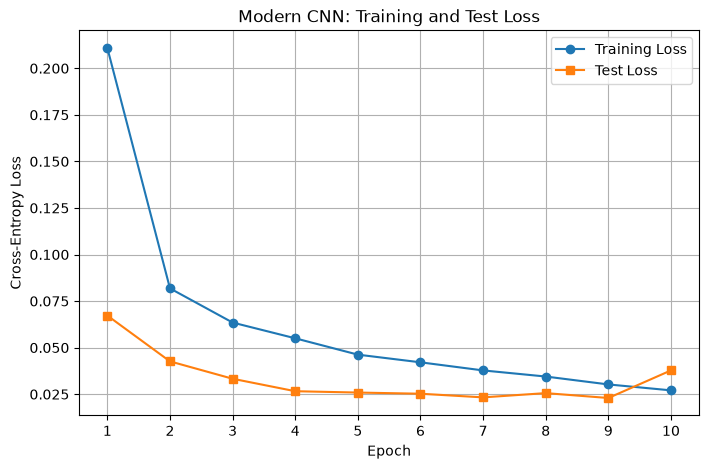

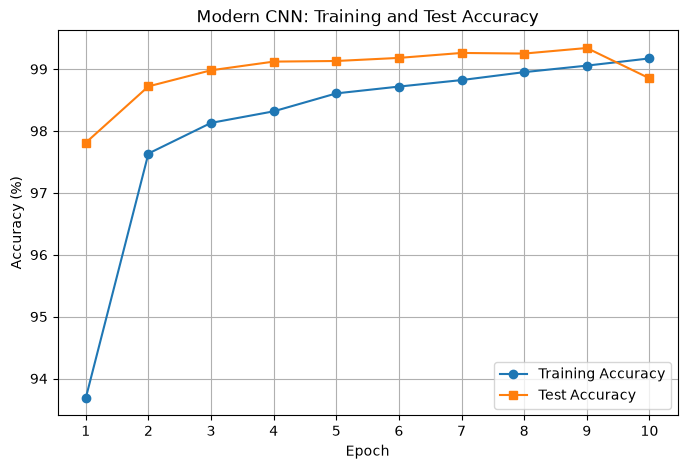

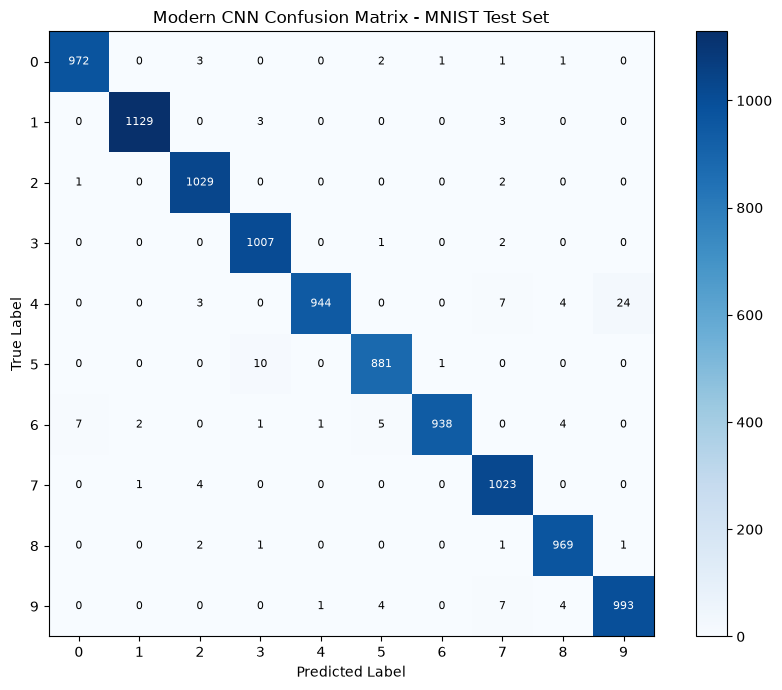

Final Modern CNN training accuracy: 99.17%
Final Modern CNN test accuracy: 98.85%


In [37]:

# Q2(b): Prepare data and train Modern CNN

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Use the same GPU/CPU device as before
print("Using device:", device)

# 1. Transform: pad 28x28 MNIST images to 32x32
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

# Reuse the downloaded MNIST dataset
trainset = torchvision.datasets.MNIST(
    root='./data/mnist',
    train=True,
    download=False,
    transform=transform
)

testset = torchvision.datasets.MNIST(
    root='./data/mnist',
    train=False,
    download=False,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# 2. Initialize a fresh Modern CNN
modern_cnn = ModernSmallCNN().to(device)

# 3. Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modern_cnn.parameters(), lr=0.001)

epochs = 10

train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# 4. Training and evaluation
for epoch in range(epochs):

    # Training phase
    modern_cnn.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in trainloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = modern_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct_train += (predictions == labels).sum().item()
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100.0 * correct_train / total_train

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Test phase
    modern_cnn.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = modern_cnn(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            correct_test += (predictions == labels).sum().item()
            total_test += labels.size(0)

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = 100.0 * correct_test / total_test

    test_losses.append(epoch_test_loss)
    test_accuracies.append(epoch_test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_acc:.2f}% | "
        f"Test Loss: {epoch_test_loss:.4f} | "
        f"Test Accuracy: {epoch_test_acc:.2f}%"
    )

# 5. Plot training and test loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses,
         marker='o', label='Training Loss')
plt.plot(range(1, epochs + 1), test_losses,
         marker='s', label='Test Loss')
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Modern CNN: Training and Test Loss")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()

# 6. Plot training and test accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_accuracies,
         marker='o', label='Training Accuracy')
plt.plot(range(1, epochs + 1), test_accuracies,
         marker='s', label='Test Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Modern CNN: Training and Test Accuracy")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()

# 7. Calculate the test confusion matrix
confusion_matrix = torch.zeros(10, 10, dtype=torch.int64)

modern_cnn.eval()

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = modern_cnn(images)
        predictions = outputs.argmax(dim=1)

        indices = labels * 10 + predictions
        counts = torch.bincount(
            indices.cpu(), minlength=100
        )
        confusion_matrix += counts.reshape(10, 10)

plt.figure(figsize=(9, 7))
plt.imshow(confusion_matrix.numpy(), cmap='Blues')
plt.title("Modern CNN Confusion Matrix - MNIST Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

for i in range(10):
    for j in range(10):
        value = confusion_matrix[i, j].item()
        plt.text(
            j, i, str(value),
            ha='center', va='center',
            color='white' if value > confusion_matrix.max().item() * 0.5
            else 'black',
            fontsize=8
        )

plt.tight_layout()
plt.show()

# 8. Final results
print(f"Final Modern CNN training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Modern CNN test accuracy: {test_accuracies[-1]:.2f}%")


The Modern CNN achieved a training accuracy of 99.17% and a test accuracy of 98.85% after 10 epochs on the MNIST dataset. The model incorporates three convolutional layers with batch normalization, ReLU activation, and max pooling, followed by dropout in the feature extraction and classification stages. These components help the network learn useful image features while reducing overfitting. The small difference between training and test accuracy indicates good generalization to unseen images. However, the final test accuracy is slightly lower than that of LeNet-5, which achieved 98.92% test accuracy. Therefore, the Modern CNN did not outperform LeNet-5 in this particular experiment.

LeNet-5 Epoch 1/10 | Train Acc: 92.39% | Test Acc: 97.45%
LeNet-5 Epoch 2/10 | Train Acc: 97.72% | Test Acc: 98.47%
LeNet-5 Epoch 3/10 | Train Acc: 98.44% | Test Acc: 98.73%
LeNet-5 Epoch 4/10 | Train Acc: 98.77% | Test Acc: 98.32%
LeNet-5 Epoch 5/10 | Train Acc: 99.03% | Test Acc: 98.89%
LeNet-5 Epoch 6/10 | Train Acc: 99.14% | Test Acc: 98.77%
LeNet-5 Epoch 7/10 | Train Acc: 99.26% | Test Acc: 98.69%
LeNet-5 Epoch 8/10 | Train Acc: 99.36% | Test Acc: 98.93%
LeNet-5 Epoch 9/10 | Train Acc: 99.44% | Test Acc: 98.77%
LeNet-5 Epoch 10/10 | Train Acc: 99.51% | Test Acc: 98.78%


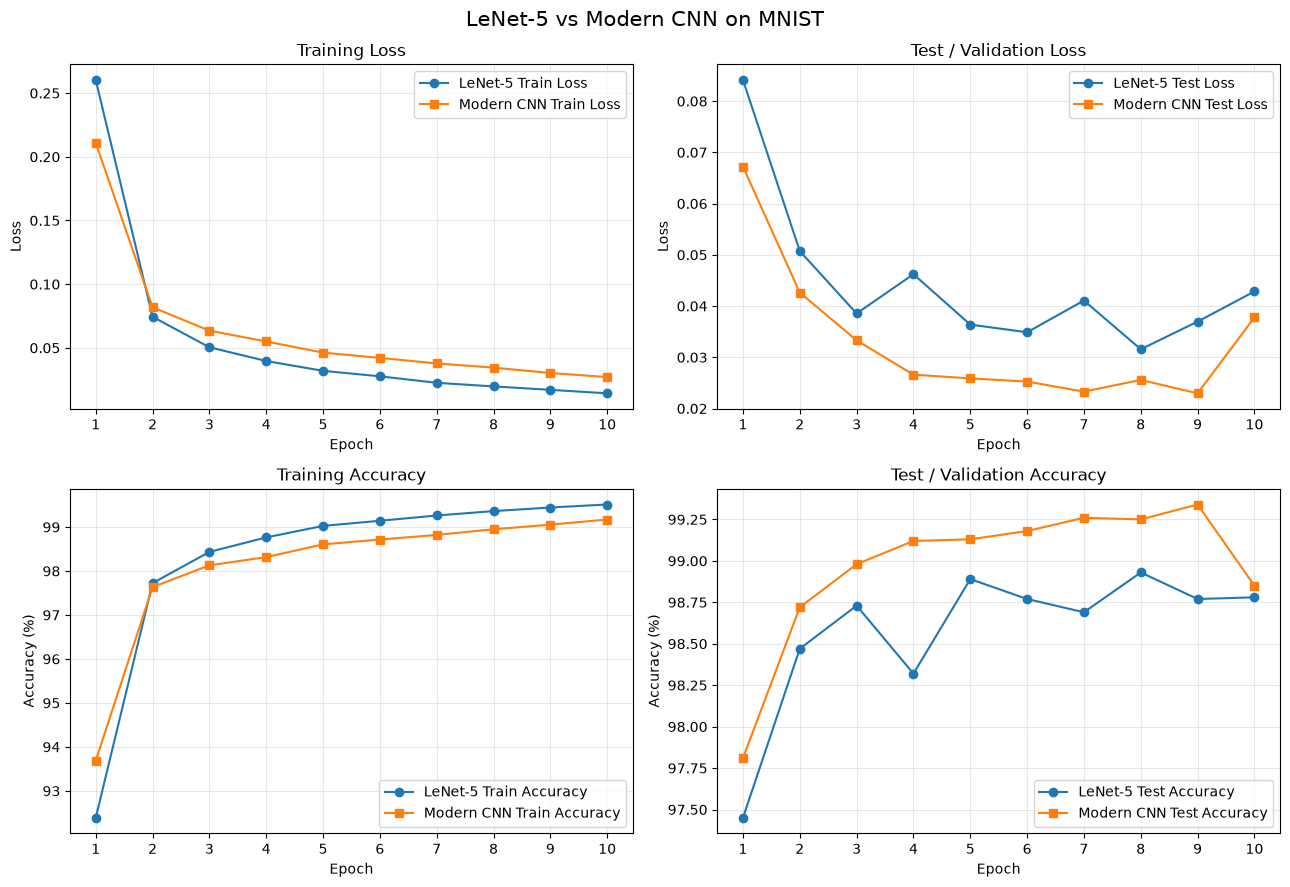


Final comparison
LeNet-5 test accuracy: 98.78%
Modern CNN test accuracy: 98.85%
Figure saved as q2c_model_comparison.png


In [38]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Use the Modern CNN histories already collected in Q2(b)
modern_train_losses = train_losses.copy()
modern_test_losses = test_losses.copy()
modern_train_accuracies = train_accuracies.copy()
modern_test_accuracies = test_accuracies.copy()

# Recreate the original 28x28 MNIST loaders for LeNet-5
lenet_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

lenet_trainset = torchvision.datasets.MNIST(
    root='./data/mnist',
    train=True,
    download=False,
    transform=lenet_transform
)

lenet_testset = torchvision.datasets.MNIST(
    root='./data/mnist',
    train=False,
    download=False,
    transform=lenet_transform
)

lenet_trainloader = torch.utils.data.DataLoader(
    lenet_trainset, batch_size=64, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)

lenet_testloader = torch.utils.data.DataLoader(
    lenet_testset, batch_size=64, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

# Train LeNet-5 again, preserving its histories separately
lenet_model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(lenet_model.parameters(), lr=0.001)

epochs = 10

lenet_train_losses = []
lenet_test_losses = []
lenet_train_accuracies = []
lenet_test_accuracies = []

for epoch in range(epochs):
    # Training
    lenet_model.train()
    loss_sum, correct, total = 0.0, 0, 0

    for images, labels in lenet_trainloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = lenet_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    lenet_train_losses.append(loss_sum / total)
    lenet_train_accuracies.append(100 * correct / total)

    # Test / validation
    lenet_model.eval()
    loss_sum, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in lenet_testloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = lenet_model(images)
            loss = criterion(outputs, labels)

            loss_sum += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    lenet_test_losses.append(loss_sum / total)
    lenet_test_accuracies.append(100 * correct / total)

    print(
        f"LeNet-5 Epoch {epoch + 1}/{epochs} | "
        f"Train Acc: {lenet_train_accuracies[-1]:.2f}% | "
        f"Test Acc: {lenet_test_accuracies[-1]:.2f}%"
    )

# Four-panel comparison figure
epoch_numbers = range(1, epochs + 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Training loss
axes[0, 0].plot(epoch_numbers, lenet_train_losses,
                marker='o', label='LeNet-5 Train Loss')
axes[0, 0].plot(epoch_numbers, modern_train_losses,
                marker='s', label='Modern CNN Train Loss')
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Test loss
axes[0, 1].plot(epoch_numbers, lenet_test_losses,
                marker='o', label='LeNet-5 Test Loss')
axes[0, 1].plot(epoch_numbers, modern_test_losses,
                marker='s', label='Modern CNN Test Loss')
axes[0, 1].set_title("Test / Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Training accuracy
axes[1, 0].plot(epoch_numbers, lenet_train_accuracies,
                marker='o', label='LeNet-5 Train Accuracy')
axes[1, 0].plot(epoch_numbers, modern_train_accuracies,
                marker='s', label='Modern CNN Train Accuracy')
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Test accuracy
axes[1, 1].plot(epoch_numbers, lenet_test_accuracies,
                marker='o', label='LeNet-5 Test Accuracy')
axes[1, 1].plot(epoch_numbers, modern_test_accuracies,
                marker='s', label='Modern CNN Test Accuracy')
axes[1, 1].set_title("Test / Validation Accuracy")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy (%)")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

for ax in axes.flat:
    ax.set_xticks(range(1, epochs + 1))

plt.suptitle("LeNet-5 vs Modern CNN on MNIST", fontsize=15)
plt.tight_layout()
plt.savefig("q2c_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nFinal comparison")
print(f"LeNet-5 test accuracy: {lenet_test_accuracies[-1]:.2f}%")
print(f"Modern CNN test accuracy: {modern_test_accuracies[-1]:.2f}%")
print("Figure saved as q2c_model_comparison.png")


Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Classes: ['ants', 'bees']
Training images: 244
Validation images: 153
Fine-tuning | Epoch 1/25 | Train Acc: 66.39% | Val Acc: 81.70% | Train Loss: 0.7119 | Val Loss: 0.3847
Fine-tuning | Epoch 2/25 | Train Acc: 80.33% | Val Acc: 81.70% | Train Loss: 0.4899 | Val Loss: 0.4394
Fine-tuning | Epoch 3/25 | Train Acc: 77.87% | Val Acc: 92.81% | Train Loss: 0.5757 | Val Loss: 0.2641
Fine-tuning | Epoch 4/25 | Train Acc: 79.51% | Val Acc: 86.93% | Train Loss: 0.4637 | Val Loss: 0.3065
Fine-tuning | Epoch 5/25 | Train Acc: 73.36% | Val Acc: 91.50% | Train Loss: 0.7335 | Val Loss: 0.2184
Fine-tuning | Epoch 6/25 | Train Acc: 79.92% | Val Acc: 92.16% | Train Loss: 0.4473 | Val Loss: 0.2302
Fine-tuning | Epoch 7/25 | Train Acc: 81.97% | Val Acc: 87.58% | Train Loss: 0.4794 | Val Loss: 0.3703
Fine-tuning | Epoch 8/25 | Train Acc: 85.25% | Val Acc: 90.20% | Train Loss: 0.4089 | Val Loss: 0.2485
Fine-tuning | Epoch 9/25 | Train Acc: 87.30% | 

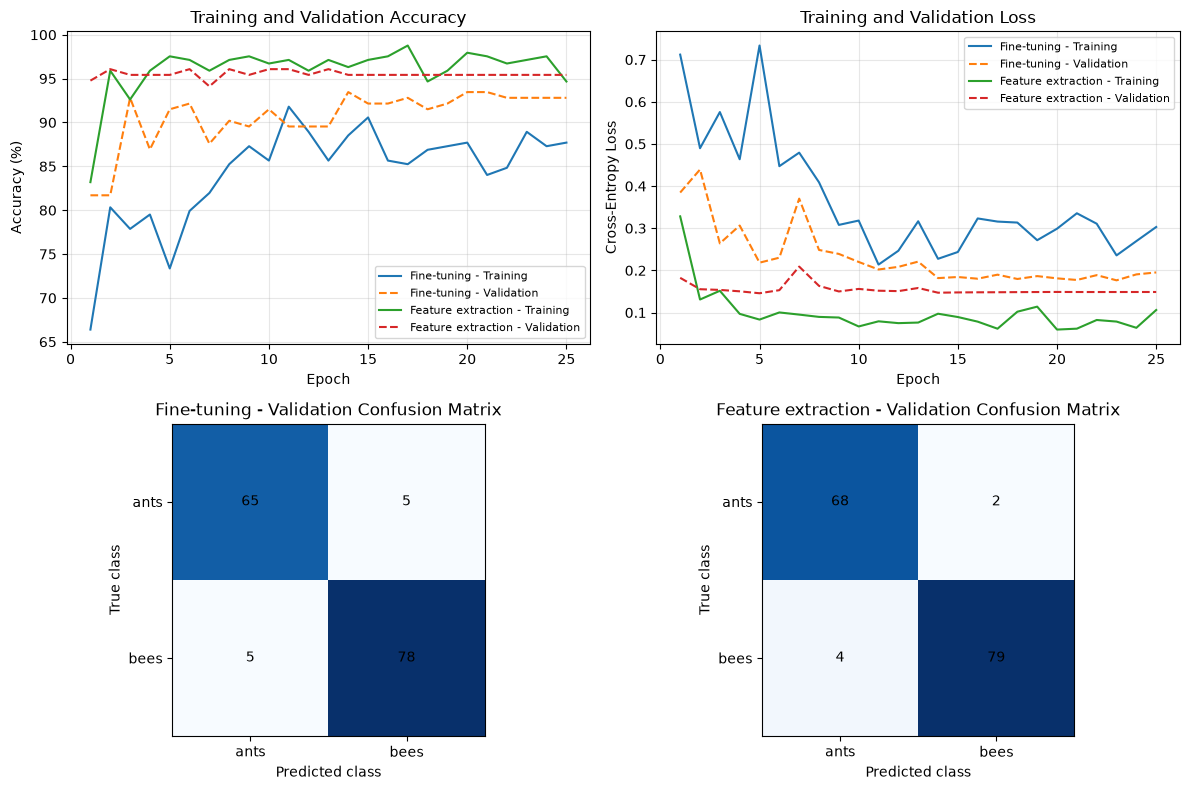

In [39]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import copy

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Image transformations
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.485, 0.456, 0.406),
        (0.229, 0.224, 0.225)
    )
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.485, 0.456, 0.406),
        (0.229, 0.224, 0.225)
    )
])

# 3. Load the already downloaded Hymenoptera dataset
batch_size = 4

trainset = torchvision.datasets.ImageFolder(
    root="./data/hymenoptera_data/train",
    transform=train_transform
)

valset = torchvision.datasets.ImageFolder(
    root="./data/hymenoptera_data/val",
    transform=val_transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

valloader = torch.utils.data.DataLoader(
    valset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

classes = trainset.classes

print("Classes:", classes)
print("Training images:", len(trainset))
print("Validation images:", len(valset))

# 4. Common training settings
criterion = nn.CrossEntropyLoss()
iterations = 25
lr = 0.001

# 5. Training and evaluation functions
def evaluate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0
    confusion = torch.zeros(
        len(classes), len(classes), dtype=torch.int64
    )

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            indices = labels * len(classes) + predictions
            counts = torch.bincount(
                indices.cpu(),
                minlength=len(classes) ** 2
            )

            confusion += counts.reshape(len(classes), len(classes))

    average_loss = running_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy, confusion.numpy()


def train_model(model, optimizer, scheduler, name,
                feature_extract=False):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(iterations):
        model.train()

        # When extracting features, keep pretrained BatchNorm
        # layers in evaluation mode so their running statistics
        # are not updated.
        if feature_extract:
            for module in model.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        val_loss, val_acc, _ = evaluate(
            model, valloader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

        scheduler.step()

        print(
            f"{name} | Epoch {epoch + 1}/{iterations} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    # Restore the best validation-accuracy checkpoint
    model.load_state_dict(best_weights)

    return history, best_acc


# 6. (a) Fine-tuning: train all layers
model_ft = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)
model_ft = model_ft.to(device)

optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=lr,
    momentum=0.9
)

scheduler_ft = optim.lr_scheduler.StepLR(
    optimizer_ft,
    step_size=7,
    gamma=0.1
)

history_ft, best_acc_ft = train_model(
    model_ft,
    optimizer_ft,
    scheduler_ft,
    "Fine-tuning"
)

# 7. (b) Feature extraction: train only the final layer
model_fe = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

for param in model_fe.parameters():
    param.requires_grad = False

model_fe.fc = nn.Linear(model_fe.fc.in_features, 2)
model_fe = model_fe.to(device)

optimizer_fe = optim.SGD(
    model_fe.fc.parameters(),
    lr=lr,
    momentum=0.9
)

scheduler_fe = optim.lr_scheduler.StepLR(
    optimizer_fe,
    step_size=7,
    gamma=0.1
)

history_fe, best_acc_fe = train_model(
    model_fe,
    optimizer_fe,
    scheduler_fe,
    "Feature extraction",
    feature_extract=True
)

# 8. Evaluate the best checkpoints
val_loss_ft, val_acc_ft, cm_ft = evaluate(
    model_ft, valloader, criterion
)

val_loss_fe, val_acc_fe, cm_fe = evaluate(
    model_fe, valloader, criterion
)

print("\nFinal comparison")
print(
    f"{'Model':<22} {'Final Train':>12} "
    f"{'Final Val':>12} {'Best Val':>12}"
)

print(
    f"{'Fine-tuning':<22} "
    f"{history_ft['train_acc'][-1]:>11.2f}% "
    f"{history_ft['val_acc'][-1]:>11.2f}% "
    f"{best_acc_ft:>11.2f}%"
)

print(
    f"{'Feature extraction':<22} "
    f"{history_fe['train_acc'][-1]:>11.2f}% "
    f"{history_fe['val_acc'][-1]:>11.2f}% "
    f"{best_acc_fe:>11.2f}%"
)

# 9. Plot accuracy and loss for both methods
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for name, history, color in [
    ("Fine-tuning", history_ft, "tab:blue"),
    ("Feature extraction", history_fe, "tab:orange")
]:
    epochs_range = range(1, iterations + 1)

    # Training and validation accuracy
    axes[0, 0].plot(
        epochs_range, history["train_acc"],
        label=f"{name} - Training"
    )
    axes[0, 0].plot(
        epochs_range, history["val_acc"],
        linestyle="--", label=f"{name} - Validation"
    )

    # Training and validation loss
    axes[0, 1].plot(
        epochs_range, history["train_loss"],
        label=f"{name} - Training"
    )
    axes[0, 1].plot(
        epochs_range, history["val_loss"],
        linestyle="--", label=f"{name} - Validation"
    )

axes[0, 0].set_title("Training and Validation Accuracy")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].legend(fontsize=8)

axes[0, 1].set_title("Training and Validation Loss")
axes[0, 1].set_ylabel("Cross-Entropy Loss")
axes[0, 1].legend(fontsize=8)

for ax in axes[0]:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)

# Plot the best-checkpoint confusion matrices
for ax, cm, name in [
    (axes[1, 0], cm_ft, "Fine-tuning"),
    (axes[1, 1], cm_fe, "Feature extraction")
]:
    ax.imshow(cm, cmap="Blues")

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center"
            )

    ax.set_title(f"{name} - Validation Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(classes)), classes)
    ax.set_yticks(range(len(classes)), classes)

plt.tight_layout()
plt.savefig(
    "q3_resnet18_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Feature extraction achieved better performance than fine-tuning, with a best validation accuracy of 96.08% compared to 93.46%. It also produced fewer misclassifications (6 vs. 10). This suggests that the pretrained ResNet18 features were already effective for distinguishing ants from bees, while freezing the pretrained layers helped prevent unnecessary changes to the learned features.